# Projet COCOMA - Coordination de satellites

* **_Decker_ _Benjamin_ _21110846_**
* **_Rahaoui_ _Ines_ _21105329_**

Dans ce notebook, nous nous intéressons à un problème d’allocation multi-agents de tâches, dans lequel des tâches d’observation doivent être attribuées à des constellations de satellites en orbite autour de la Terre, en nous inspirant de l’article *Auction-based and Distributed Optimization Approaches for Scheduling Observations in Satellite Constellations with Exclusive Orbit Portions*

In [1]:
from dataclasses import dataclass, field
from typing import List, Tuple, Dict, Optional, Set
import random 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from pydcop.dcop.objects import Variable, AgentDef
from pydcop.dcop.relations import NAryFunctionRelation
from pydcop.dcop.dcop import DCOP
import matplotlib.patches as mpatches
import pandas as pd
import time
import math


### Génération d'instances aléatoires

Pour générer nos instances, nous suivons les paramètres utilisés dans la partie **résultats** de l’article, en particulier pour les valeurs des **récompenses** (*reward*) qu'on fait varier de 10-50 pour les utilisatuers exclusifs et de 1 à 10 pour les utilisateurs non exclusif. et de la **fonction de transition** qui va etre uniforme.

Nous prenons aussi en compte la contrainte selon laquelle un satellite ne peut être assigné qu’à **au plus un utilisateur exclusif** à la fois, comme précisé dans le sujet du projet. Enfin, l’utilisateur **0** est défini par défaut comme le **planificateur central** ne possédant pas de créneaux exclusifs, conformément au modèle de l’article.


In [2]:
@dataclass
class Satellite:
    id: str
    t_start: float
    t_end: float
    capacity: int
    transition_time: float

@dataclass
class User:
    id: str
    priority: int
    exclusives: List[Tuple[str, Tuple[float, float]]] # (satellite_id, (t_start, t_end))

@dataclass
class Request:
    id: str
    user_id: str
    t_start: float
    t_end: float
    duration: float
    reward: int
    observation: List[str] = field(default_factory=list)

@dataclass
class Observation:
    id: str
    request_id: str
    user_id: str
    satellite_id: str
    t_start: float
    t_end: float
    duration: float
    reward: int
    priority: int

@dataclass
class EOSCP:
    satellites: Dict[str, Satellite]
    users: Dict[str, User]
    requests: Dict[str, Request]
    observations: Dict[str, Observation]

def set_seed(seed = None):
    random.seed(seed)

def get_exclusive_window(user: User, sat_id: str):
    """Return the exclusive window (start, end) for a user on a satellite, or None if no exclusive."""
    for sid, (win_start, win_end) in user.exclusives:
        if sid == sat_id:
            return (win_start, win_end)
    return None

def generate_instance(n_users, n_satellites, requests_per_user, observations_per_requests):
    satellites = {}
    time_horizon = 10.0

    for s in range(n_satellites):
        sid = f"s{s}"
        satellites[sid] = Satellite(sid, 
                                    0.0, 
                                    time_horizon, 
                                    random.randint(((requests_per_user * observations_per_requests * n_users) // n_satellites) + 1, 
                                                   requests_per_user * observations_per_requests * n_users), 
                                    random.uniform(0.01, 0.1))
        
    users = {}
    users["u0"] = User("u0", n_users, []) # central planner, represents users without exclusive window
    non_exclusives_sat = list(satellites.keys()) # satellites that have no exclusive user yet

    for u in range(1, n_users):
        uid = f"u{u}"
        exclusives = []
        sample = random.sample(non_exclusives_sat, random.randint(1, max(1, n_satellites // n_users))) # Every user has at least one exclusive window
        for s in sample: 
            start = random.uniform(0.0, time_horizon - 1.0)
            end = start + random.uniform(0.5, 1.5) 
            exclusives.append((s, (start, min(end, time_horizon))))
            if s in non_exclusives_sat:
                non_exclusives_sat.remove(s) # Every satellite has at most one exclusive user (every satellite shall not have at least one exclusive user)
        users[uid] = User(uid, n_users - u, exclusives=exclusives)
        
    requests, observations = {}, {}
    req_id, obs_id = 0, 0

    for uid, user in users.items():
        for i in range(requests_per_user):
            rid = f"r{req_id}"
            req_id += 1
            start = random.uniform(0.0, time_horizon - 2.0)
            end = start + random.uniform(1.0, 3.0)
            duration = random.uniform(0.05, 1.0)
            reward = random.randint(10, 50) if uid != "u0" else random.randint(1, 10)

            request = Request(rid, uid, start, min(end, time_horizon), duration, reward, [])
        
            for j in range(observations_per_requests):
                oid = f"o{obs_id}"
                obs_id += 1
                if user.exclusives:
                    sat_choices = [satellites[sid] for sid, _ in user.exclusives]
                    sat = random.choice(sat_choices)
                else:
                    sat = random.choice(list(satellites.values()))
                excl_window = get_exclusive_window(user, sat.id)
                if excl_window is not None:
                    excl_start, excl_end = excl_window
                    if excl_end - excl_start >= duration:
                        start = random.uniform(excl_start, excl_end - duration)
                        end = start + duration
                    else:
                        continue
                else:
                    if request.t_end - request.t_start >= duration:
                        start = random.uniform(request.t_start, request.t_end - duration)
                        end = start + duration
                    else:
                        continue

                obs = Observation(oid, rid, uid, sat.id, start, end, duration, reward, user.priority)
                observations[oid] = obs
                request.observation.append(oid)
                # obs = Observation(oid, rid, uid, sat, start, end, duration, reward, user.priority)
                # observations[oid] = obs

            requests[rid] = request

    return EOSCP(satellites, users, requests, observations)


Nous implémentons une fonction de visualisation permettant de reproduire le type d’affichage présenté dans la figure 2 de l’article, afin de faciliter l'analyse des solutions.

In [3]:
def visualize_plan(plan: Dict[str, List[Tuple[Observation, float]]], 
                   eoscp_instance: EOSCP,
                   figsize=(12, 6)):
    
    satellites = eoscp_instance.satellites
    users = eoscp_instance.users
    
    # Color map for users (u0 = green, u1 = red, u2 = blue, etc.)
    user_colors = {
        'u0': '#90EE90',  # light green
        'u1': '#FF6B6B',  # red
        'u2': '#6B9EFF',  # blue
        'u3': '#FFD93D',  # yellow
        'u4': '#9B59B6',  # purple
    }
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Get sorted satellite IDs
    sat_ids = sorted(satellites.keys())
    sat_to_y = {sat_id: i for i, sat_id in enumerate(sat_ids)}
    
    # Get time range from all observations
    all_times = []
    for sat_id, scheduled in plan.items():
        for obs, t in scheduled:
            all_times.append(t)
            all_times.append(t + obs.duration)
    
    for uid in users.values():
        for sat_id, (win_start, win_end) in uid.exclusives:
            all_times.append(win_start)
            all_times.append(win_end)
    
    if all_times:
        time_min = min(all_times) - 0.5
        time_max = max(all_times) + 0.5
    else:
        time_min = 0
        time_max = 10
    
    # Draw exclusive windows (hatched areas)
    for uid, user in users.items():
        for sat_id, (win_start, win_end) in user.exclusives:
            if sat_id in sat_to_y:
                y_pos = sat_to_y[sat_id]
                # Draw hatched rectangle for exclusive window
                color = user_colors.get(uid, '#CCCCCC')
                rect = mpatches.Rectangle((win_start, y_pos - 0.4), 
                                         win_end - win_start, 0.8,
                                         hatch='///', 
                                         facecolor=color,
                                         edgecolor='gray',
                                         linewidth=1)
                ax.add_patch(rect)
    
    # Draw scheduled observations
    for sat_id, scheduled in sorted(plan.items()):
        y_pos = sat_to_y[sat_id]
        for obs, t in sorted(scheduled, key=lambda x: x[1]):
            user_id = obs.user_id
            color = user_colors.get(user_id, '#CCCCCC')
            
            # Draw rectangle for observation
            rect = mpatches.Rectangle((t, y_pos - 0.35), 
                                     obs.duration, 0.7,
                                     facecolor=color,
                                     edgecolor='black',
                                     linewidth=1.5)
            ax.add_patch(rect)
            
            # Add label
            ax.text(t + obs.duration / 2, y_pos, obs.id,
                   ha='center', va='center', fontsize=8, fontweight='bold')
    
    # Set axis properties
    ax.set_xlim(time_min, time_max)
    ax.set_ylim(-0.5, len(sat_ids) - 0.5)
    
    ax.set_xlabel('Time', fontsize=12)
    ax.set_ylabel('Satellites', fontsize=12)
    
    # Set y-axis ticks and labels
    ax.set_yticks(range(len(sat_ids)))
    ax.set_yticklabels(sat_ids)
    
    # Add grid
    ax.grid(True, axis='x', alpha=0.3)
    
    # Create legend for users
    legend_patches = []
    for uid in sorted(users.keys()):
        color = user_colors.get(uid, '#CCCCCC')
        legend_patches.append(mpatches.Patch(facecolor=color, edgecolor='black', label=uid))
    
    ax.legend(handles=legend_patches, loc='upper right', title='Users')
    
    plt.tight_layout()
    return fig

### Algorithme Greedy

Nous implémentons l'**Algorithme 1 (greedy)** de l'article pour obtenir une solution de référence (*baseline*). Cet algorithme glouton constitue la base de plusieurs solveurs présentés dans l'article.

#### Principe de l'algorithme

L'algorithme greedy fonctionne selon les étapes suivantes:

1. **Tri des observations** : Les observations sont triées par ordre de **priorité** (utilisateurs exclusifs d'abord) et par **date de début** (*t_start*)
2. **Insertion séquentielle** : Pour chaque observation dans l'ordre trié :
   - Chercher le **premier créneau disponible** (*first_slot*) sur le satellite associé
   - Vérifier les contraintes de **capacité**, **transition** et **fenêtres temporelles**
   - Si un créneau valide est trouvé, planifier l'observation
3. **Respect de la contrainte d'unicité** : Au plus **une observation par requête** est planifiée

#### Complexité et performances

Comme indiqué dans l'article, cet algorithme glouton est **rapide** et fournit des solutions de **bonne qualité**, bien que non nécessairement optimales. Il sert de **baseline** pour évaluer les algorithmes distribués plus sophistiqués présentés dans les sections suivantes.

In [4]:
def insert_sorted(plan_sat: List[Tuple[Observation, float]], obs: Observation, t: float):
    """Insère (obs,t) en gardant l'ordre croissant des t."""
    i = 0
    while i < len(plan_sat) and plan_sat[i][1] <= t:
        i += 1

    plan_sat.insert(i, (obs, t))

def first_slot(obs: Observation, plan: Dict[str, List[Tuple[Observation, float]]], satellites: Dict[str, Satellite]):
    """
    Renvoie le premier slot candidat dans lequel planifier une observation
    """
    sat = satellites[obs.satellite_id]
    scheduled = plan.get(sat.id, [])

    # Check capacity constraint
    if len(scheduled) >= sat.capacity:
        return None

    # No scheduled observations yet
    if not scheduled:
        if obs.t_start + obs.duration <= obs.t_end:
            return obs.t_start
        return None

    # Try before first scheduled observation
    first_obs, first_t = scheduled[0]
    candidate = obs.t_start
    if candidate + obs.duration + sat.transition_time <= first_t:
        if candidate + obs.duration <= obs.t_end:
            return candidate

    # Try between consecutive scheduled observations
    for i in range(len(scheduled) - 1):
        curr_obs, curr_t = scheduled[i]
        next_obs, next_t = scheduled[i + 1]
        
        curr_end = curr_t + curr_obs.duration
        candidate = max(obs.t_start, curr_end + sat.transition_time)
        
        if candidate + obs.duration + sat.transition_time <= next_t:
            if candidate + obs.duration <= obs.t_end:
                return candidate

    # Try after last scheduled observation
    last_obs, last_t = scheduled[-1]
    last_end = last_t + last_obs.duration
    candidate = max(obs.t_start, last_end + sat.transition_time)
    
    if candidate + obs.duration <= obs.t_end:
        return candidate

    return None

def greedy_schedule(observations: List[Observation],
                            satellites: Dict[str, Satellite],
                            base_plan: Optional[Dict[str, List[Tuple[Observation, float]]]] = None,
                            forbidden_requests: Optional[Set[str]] = None):
    """
    Glouton qui planifie une liste d'observations en plus d'un éventuel plan existant
    On peut ignorer certaines requêtes via forbidden_requests.
    """
    plan = {sid: [] for sid in satellites}
    total_reward = 0
    if base_plan:
        # copie profonde simple (listes de tuples)
        for sid, lst in base_plan.items():
            plan[sid] = list(lst)

    served_requests: Set[str] = set()
    # requêtes déjà servies par base_plan
    for sid, lst in plan.items():
        for o, _t in lst:
            served_requests.add(o.request_id)

    if forbidden_requests:
        served_requests |= set(forbidden_requests)

    obs_sorted = sorted(observations, key=lambda o: (o.priority, o.t_start))

    for obs in obs_sorted:
        if obs.request_id in served_requests:
            continue
        t = first_slot(obs, plan, satellites)
        if t is not None:
            insert_sorted(plan[obs.satellite_id], obs, t)
            total_reward += obs.reward
            served_requests.add(obs.request_id)

    return plan, total_reward

#### Test de la méthode greedy

Nous utilisons la fonction de visualisation afin d’obtenir un aperçu de ce à quoi peut ressembler la résolution d’un problème avec l’algorithme glouton, et de nous assurer de la cohérence des solutions produites.


Reward total (greedy EOSCP) : 85


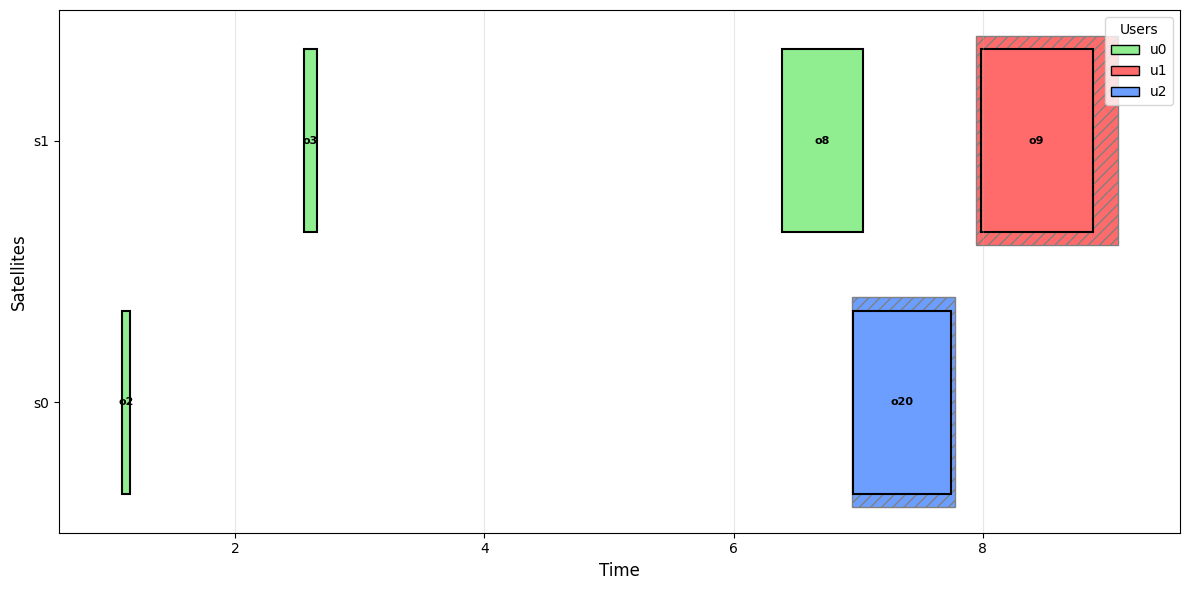

In [5]:
eoscp = generate_instance(n_users=3, n_satellites=2, requests_per_user=3, observations_per_requests=3)
obs_all = list(eoscp.observations.values())
plan_greedy, reward_greedy = greedy_schedule(obs_all, eoscp.satellites)
print(f"Reward total (greedy EOSCP) : {reward_greedy}")
visualize_plan(plan_greedy, eoscp)
plt.show()

## Partie 1 : Optimisation de Contraintes Distribuées

Cette partie implémente l'approche par **DCOP** (*Distributed Constraint Optimization Problem*) présentée dans la **Section 5** de l'article pour résoudre le problème EOSCSP.

#### Construction du DCOP (Section 5.3)

Pour la construction du DCOP conformément à la **Section 5.3** de l'article, nous suivons le modèle séquentiel **SDCOP** (*Sequential DCOP*, Algorithme 5) :

1. **Agents** : Les utilisateurs exclusifs pouvant planifier la requête courante
2. **Variables** : $x_{e,o}$ binaires indiquant si l'utilisateur planifie l'observation $o$ durant la fenêtre exclusive $e$
3. **Contraintes** :
   - **(15)** Au plus une observation par requête 
   - **(16)** Contrainte de capacité satellite
   - **(17)** Au plus un agent par observation
   - **(18)** Coût d'intégration

#### Implémentation

Nous choisissons d'utiliser une pondération définie par $\pi_i = \text{reward} \times \text{priority}$ pour évaluer le coût associé à chaque observation, conformément à l'équation (18) de l'article.

In [6]:
def build_dcop(request: Request, eoscp_instance: EOSCP, 
                              current_schedules: Dict[str, List[Tuple[Observation, float]]]):

    BIG_M = 10_000
    
    satellites = eoscp_instance.satellites
    users = eoscp_instance.users
    observations = eoscp_instance.observations
    
    # Déterminer les utilisateurs exclusifs qui peuvent planifier cette requête
    
    agents_set = set()
    o_u_r = {} 
    
    for uid, user in users.items():
        if uid == "u0":
            continue
        
        o_u_r[uid] = []
        for obs in observations.values():
            if obs.request_id != request.id:
                continue

            for (sat_id, (win_start, win_end)) in user.exclusives:
                if obs.satellite_id != sat_id:
                    continue

                if max(win_start, obs.t_start) < min(win_end, obs.t_end):
                    o_u_r[uid].append(obs)
                    agents_set.add(uid)
                    break

    if not agents_set:
        return None, {}

    # Créer les agents
    agents = {uid: AgentDef(uid, capacity=float('inf')) for uid in agents_set}
    
    # Créer les variables
    variables = {}
    var_to_obs = {} 
    
    for uid in agents_set:
        for obs in o_u_r[uid]:
            for (sat_id, (win_start, win_end)) in users[uid].exclusives:
                if sat_id != obs.satellite_id:
                    continue
                # Variable x_{e,o} où e est identifiée par (uid, sat_id, fenêtre)
                var_id = f"x_{uid}_{sat_id}_{obs.id}"
                variables[var_id] = Variable(var_id, [0, 1])
                var_to_obs[var_id] = (uid, obs)
                break
    
    constraints = {}
    
    # Contrainte (15): Au plus une observation est planifiée pour chaque requete
    def c15(**kwargs):
        s = sum(kwargs.values())
        return 0 if s <= 1 else -BIG_M
    
    for uid in agents_set:
        for obs in o_u_r[uid]:
            vars_for_obs = [var for var_id, var in variables.items() 
                          if var_to_obs[var_id][1].id == obs.id]
            if len(vars_for_obs) > 1:
                rel = NAryFunctionRelation(c15, vars_for_obs, 
                                          name=f"c15_{obs.id}", f_kwargs=True)
                constraints[rel.name] = rel
    
    # Contrainte (16): Pas de surcharge par satellite
    def c16(max_cap):
        def f(**kwargs):
            s = sum(kwargs.values())
            return 0 if s <= max_cap else -BIG_M
        return f
    
    for sat_id in satellites.keys():
        cap = satellites[sat_id].capacity
        sat_vars = []
        
        for var_id, var in variables.items():
            uid, obs = var_to_obs[var_id]
            if obs.satellite_id == sat_id:
                sat_vars.append(var)
        
        if sat_vars:
            remaining_capacity = cap - len(current_schedules.get(sat_id, []))
            
            rel = NAryFunctionRelation(
                c16(remaining_capacity), 
                sat_vars,
                name=f"c16_{sat_id}", 
                f_kwargs=True
            )
            constraints[rel.name] = rel
    
    # Contrainte (17): Au plus un agent par observation
    def c17(**kwargs):
        s = sum(kwargs.values())
        return 0 if s <= 1 else -BIG_M
    
    for obs_id in set(obs.id for uid in agents_set for obs in o_u_r[uid]):
        obs = observations[obs_id]
        vars_for_obs = [var for var_id, var in variables.items() 
                       if var_to_obs[var_id][1].id == obs_id]
        if len(vars_for_obs) > 1:
            rel = NAryFunctionRelation(c17, vars_for_obs,
                                      name=f"c17_obs_{obs_id}", f_kwargs=True)
            constraints[rel.name] = rel
    
    # Contrainte (18): Soft constraint - coût d'intégration
    for var_id, var in variables.items():
        uid, obs = var_to_obs[var_id]
        reward_val = obs.reward * obs.priority

        def c18(val):
            def f(x):
                return val if x == 1 else 0
            return f
        
        rel = NAryFunctionRelation(c18(reward_val), [var], 
                                  name=f"c18_{var_id}")
        constraints[rel.name] = rel
    
    dcop = DCOP(name=f"EOSCP_DCOP_req_{request.id}", objective="max")
    dcop.add_agents(agents)

    for var in variables.values():
        dcop.add_variable(var)

    for rel in constraints.values():
        dcop.add_constraint(rel)
    
    return dcop, var_to_obs

In [7]:
def sdcop_eoscsp_solver(eoscp_instance: EOSCP, algorithm='dpop'):
    
    satellites = eoscp_instance.satellites
    users = eoscp_instance.users
    requests = eoscp_instance.requests
    observations = eoscp_instance.observations
    
    M_u = {}
    
    for uid, user in users.items():
        if uid == "u0":
            M_u[uid] = {sat_id: [] for sat_id in satellites.keys()}
            continue
        
        user_obs = [obs for obs in observations.values() if obs.user_id == uid]
        
        if user_obs:
            plan_u, reward_u = greedy_schedule(user_obs, satellites)
            M_u[uid] = plan_u
        else:
            M_u[uid] = {sat_id: [] for sat_id in satellites.keys()}
    
    # On trie les requetes par leur ordre de fin
    sorted_requests = sorted(requests.values(), key=lambda r: (r.t_end, r.t_start))

    
    for req in sorted_requests:
        removed_obs = {}
        for uid, plan_u in M_u.items():
            removed_obs[uid] = []
            for sat_id in plan_u.keys():
                removed_from_sat = [(obs, t) for obs, t in plan_u[sat_id] 
                                   if obs.request_id == req.id]
                removed_obs[uid].extend(removed_from_sat)
                plan_u[sat_id] = [(obs, t) for obs, t in plan_u[sat_id] 
                                 if obs.request_id != req.id]
        
        current_schedules = {sat_id: [] for sat_id in satellites.keys()}
        for uid, plan_u in M_u.items():
            for sat_id, scheduled in plan_u.items():
                current_schedules[sat_id].extend(scheduled)
        
        dcop_req, var_to_obs = build_dcop(req, eoscp_instance, current_schedules)
        
        if dcop_req is None:
            for uid, obs_list in removed_obs.items():
                for obs, t in obs_list:
                    M_u[uid][obs.satellite_id].append((obs, t))
            continue

        solution = solve_dcop_with_pydcop(dcop_req, algorithm=algorithm, timeout=10)
        
        if not solution:
            for uid, obs_list in removed_obs.items():
                for obs, t in obs_list:
                    M_u[uid][obs.satellite_id].append((obs, t))
            continue
        
        request_assigned = False 
        
        for var_name, value in solution.items():
            if value == 1 and not request_assigned: 
                parts = var_name.split('_')
                if len(parts) >= 4:
                    uid = parts[1]
                    obs_id = '_'.join(parts[3:])
                    obs = observations.get(obs_id)
                    if obs:
                        t = first_slot(obs, M_u[uid], satellites)
                        if t is not None:
                            M_u[uid][obs.satellite_id].append((obs, t))
                            request_assigned = True

        if not request_assigned:
            for uid, obs_list in removed_obs.items():
                for obs, t in obs_list:
                    M_u[uid][obs.satellite_id].append((obs, t))
    
    assigned_u0_obs_ids = set()
    for uid in users.keys():
        if uid == "u0":
            continue
        for sat_id, scheduled in M_u[uid].items():
            for obs, _ in scheduled:
                if obs.user_id == "u0":
                    assigned_u0_obs_ids.add(obs.id)
    

    u0_obs = [obs for obs in observations.values()
              if obs.user_id == "u0" and obs.id not in assigned_u0_obs_ids]
    
    if u0_obs:
        occupied_slots = {sat_id: [] for sat_id in satellites.keys()}
        for uid, plan_u in M_u.items():
            for sat_id, scheduled in plan_u.items():
                occupied_slots[sat_id].extend(scheduled)
        
        served_requests = set()  
        for obs in sorted(u0_obs, key=lambda o: (o.priority, o.t_start)):
            if obs.request_id in served_requests:  
                continue
            t = first_slot(obs, occupied_slots, satellites)
            if t is not None:
                M_u["u0"][obs.satellite_id].append((obs, t))
                occupied_slots[obs.satellite_id].append((obs, t))
                served_requests.add(obs.request_id)  

    total_reward = 0
    total_observations = 0
    
    for uid in M_u.keys():
        n_obs_user = 0
        if isinstance(M_u[uid], dict):
            for sat_id, scheduled in M_u[uid].items():
                n_obs_user += len(scheduled)
                total_observations += len(scheduled)
                for obs, _ in scheduled:
                    total_reward += obs.reward
    
    return M_u

In [8]:
def solve_dcop_with_pydcop(dcop, algorithm='dpop', timeout=10, return_metrics=False):
    try:
        from pydcop.algorithms import AlgorithmDef, load_algorithm_module
        from pydcop.distribution.adhoc import distribute
        from pydcop.infrastructure.run import run_local_thread_dcop
        
        algo_module = load_algorithm_module(algorithm)
        
        # Choisir le type de graphe compatible avec l'algorithme
        graph_type = getattr(algo_module, 'GRAPH_TYPE', 'factor_graph')
        if graph_type == 'pseudotree':
            from pydcop.computations_graph import pseudotree as cg_builder
        elif graph_type == 'constraints_hypergraph':
            from pydcop.computations_graph import constraints_hypergraph as cg_builder
        else:
            from pydcop.computations_graph import factor_graph as cg_builder
        
        cg = cg_builder.build_computation_graph(dcop)

        algo_def = AlgorithmDef.build_with_default_param(
            algorithm,
            parameters_definitions=algo_module.algo_params,
            mode=dcop.objective
        )
        
        def safe_computation_memory(comp):
            try:
                if hasattr(algo_module, 'computation_memory'):
                    return algo_module.computation_memory(comp)
            except Exception:
                pass
            return 1

        def safe_communication_load(c, n):
            try:
                if hasattr(algo_module, 'communication_load'):
                    return algo_module.communication_load(c, n)
            except Exception:
                pass
            return 1

        distribution = distribute(
            cg,
            dcop.agents.values(),
            computation_memory=safe_computation_memory,
            communication_load=safe_communication_load
        )
        
        orchestrator = run_local_thread_dcop(
            algo_def,
            cg,
            distribution,
            dcop,
            10_000
        )
        
        try:
            orchestrator.deploy_computations()
            orchestrator.run(timeout=timeout)
            orchestrator.wait_ready()
            
            end_metrics = orchestrator.end_metrics()
            solution = end_metrics.get('assignment', None)
            
            if return_metrics:
                metrics_dict = dict(end_metrics)
                metrics_dict['algorithm'] = algorithm
                return solution, metrics_dict
            
            return solution
        finally:
            try:
                orchestrator.stop_agents(timeout=5)
                orchestrator.stop()
            except Exception:
                pass
        
    except Exception as e:
        print(f"Erreur lors de la résolution du DCOP ({algorithm}): {e}")
        if return_metrics:
            return None, {'error': str(e), 'algorithm': algorithm}
        return None


Instance: 2 users exclusifs, 2 satellites, 9 requêtes



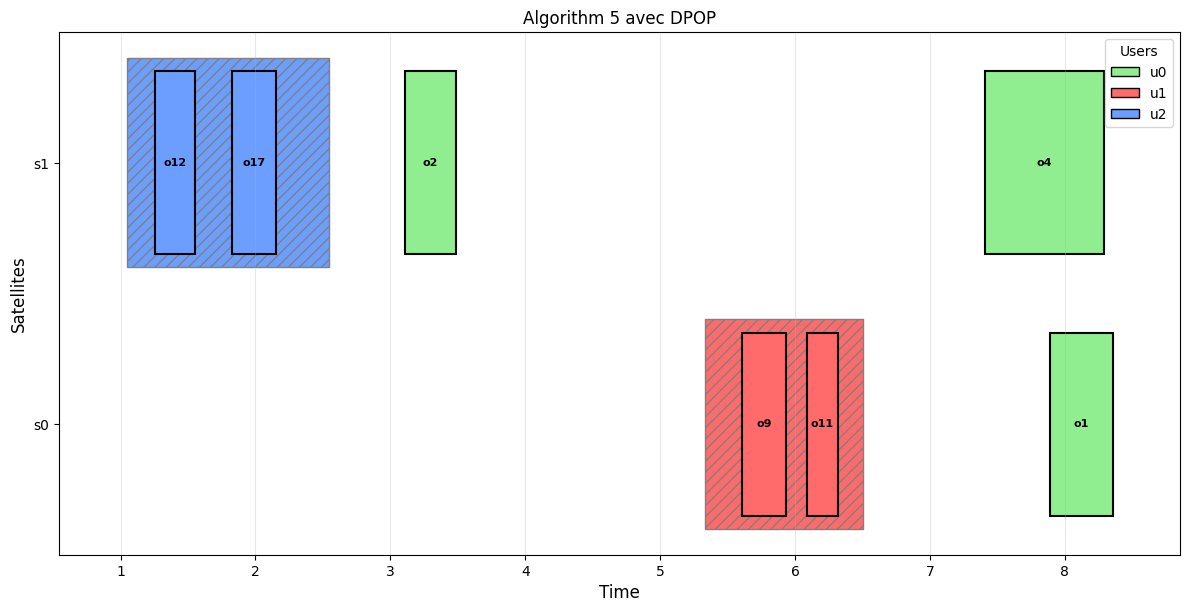

In [9]:
import warnings
import logging

warnings.filterwarnings('ignore')

logging.getLogger('pydcop').setLevel(logging.CRITICAL)
logging.getLogger('infrastructure').setLevel(logging.CRITICAL)


#set_seed(42)
test_inst_dpop = generate_instance(n_users=3, n_satellites=2, requests_per_user=3, observations_per_requests=2)

print(f"Instance: {len(test_inst_dpop.users)-1} users exclusifs, "
      f"{len(test_inst_dpop.satellites)} satellites, "
      f"{len(test_inst_dpop.requests)} requêtes\n")

# Exécuter Algorithm 5 avec DPOP
result_dpop = sdcop_eoscsp_solver(test_inst_dpop, algorithm='dpop')

# Calculer les statistiques
final_plan_dpop = {sat_id: [] for sat_id in test_inst_dpop.satellites.keys()}
for uid, plan_u in result_dpop.items():
    for sat_id, scheduled in plan_u.items():
        final_plan_dpop[sat_id].extend(scheduled)

total_obs = sum(len(v) for v in final_plan_dpop.values())
total_reward = sum(obs.reward for sat_scheduled in final_plan_dpop.values() 
                    for obs, _ in sat_scheduled)

# Visualiser
fig_dpop = visualize_plan(final_plan_dpop, test_inst_dpop)
plt.title("Algorithm 5 avec DPOP")
plt.show()



## Comparaison des solveurs DCOP

Nous testons différents solveurs de DCOP (DPOP, MGM, DSA, Max-Sum) en les comparant entre eux, en prenant comme **baseline** l’algorithme *greedy* présenté précédemment. Les comparaisons sont réalisées selon deux critères principaux : les **récompenses obtenues** (*rewards*) et le *temps d’exécution*.

Afin de modéliser des instances avec beaucoup de conflits, nous utilisons des paramètres similaires à ceux décrits dans la partie résultats de l’article tout en les changeant légèrement pour respecter les contraintes du sujet et de nos machines. Les expériences sont ainsi menées avec 4 satellites, 4 utilisateurs exclusifs (1 par satellite), 10 observations par requête, et un nombre de requêtes variant de 2 à 16, avec un pas de 2.


DPOP:  78 (50.227s) | MGM:  78 (55.851s) | DSA:  78 (56.326s) | MAXSUM:  78 (56.112s) | 
DPOP: 103 (100.337s) | MGM: 103 (110.526s) | DSA: 103 (111.609s) | MAXSUM: 103 (111.956s) | 
DPOP: 137 (130.329s) | MGM: 129 (144.045s) | DSA: 137 (145.134s) | MAXSUM: 137 (145.400s) | 
DPOP: 142 (130.410s) | MGM: 142 (145.172s) | DSA: 142 (147.071s) | MAXSUM: 142 (146.605s) | 
DPOP: 147 (210.519s) | MGM: 109 (232.459s) | DSA: 147 (233.816s) | MAXSUM: 147 (235.284s) | 
DPOP: 223 (200.551s) | MGM: 222 (223.230s) | DSA: 343 (225.053s) | MAXSUM: 223 (224.412s) | 
DPOP: 173 (240.631s) | MGM: 173 (267.558s) | DSA: 173 (269.925s) | MAXSUM: 173 (268.539s) | 


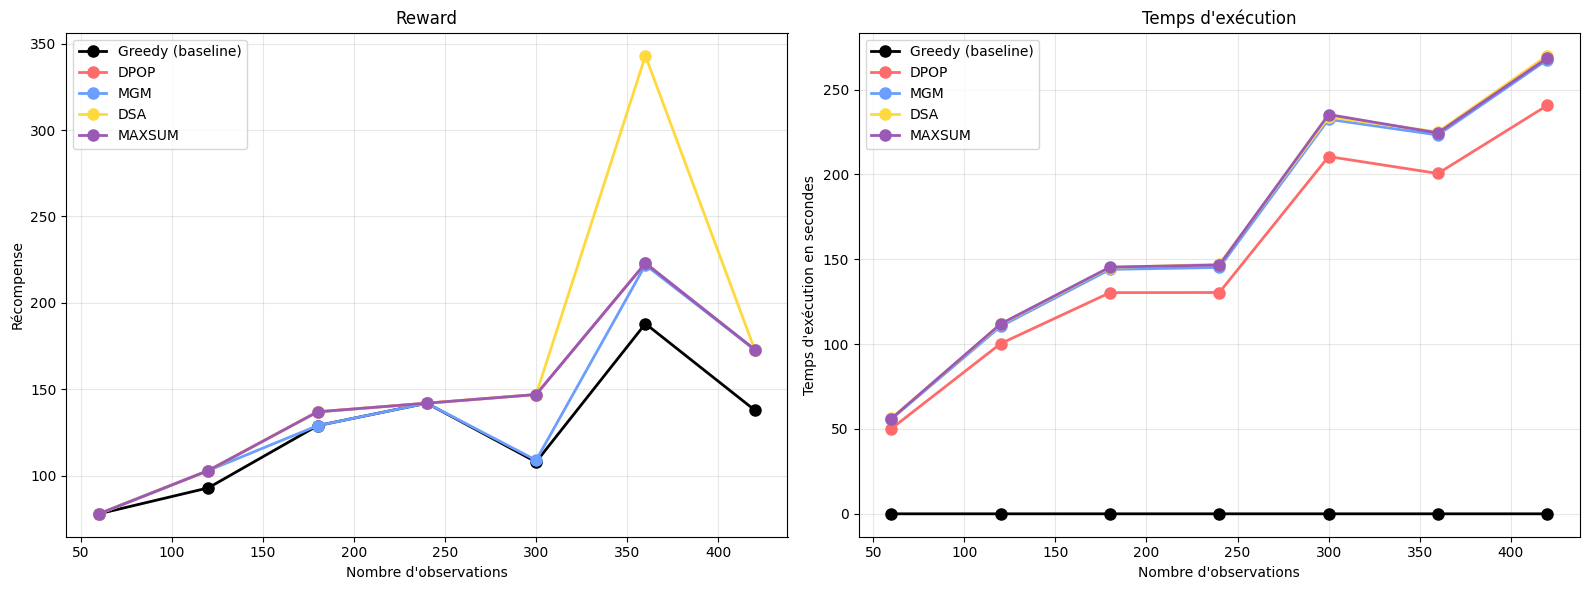

In [10]:
n_sat = 3
n_users = 3
n_obs = 10
algorithms = ['dpop', 'mgm', 'dsa', 'maxsum']

requests_range = list(range(2, 16, 2)) 

results = {
    'n_requests': [],
    'total_observations': [],
    'greedy_reward': [],
    'greedy_time': [],
}

for algo in algorithms:
    results[f'{algo}_reward'] = []
    results[f'{algo}_time'] = []

for n_requests in requests_range:
    total_obs = n_requests * n_users * n_obs
    
    test_instance = generate_instance(
        n_users=n_users,
        n_satellites=n_sat,
        requests_per_user=n_requests,
        observations_per_requests =n_obs
    )
    
    start = time.time()
    obs_all = list(test_instance.observations.values())
    plan_greedy, reward_greedy = greedy_schedule(obs_all, test_instance.satellites)
    time_greedy = time.time() - start
    
    results['n_requests'].append(n_requests)
    results['total_observations'].append(total_obs)
    results['greedy_reward'].append(reward_greedy)
    results['greedy_time'].append(time_greedy)
    
    
    for algo in algorithms:

        start = time.time()
        result_dcop = sdcop_eoscsp_solver(test_instance, algorithm=algo)
        time_algo = time.time() - start
        
        final_plan = {sat_id: [] for sat_id in test_instance.satellites.keys()}
        for uid, plan_u in result_dcop.items():
            for sat_id, scheduled in plan_u.items():
                final_plan[sat_id].extend(scheduled)
        
        reward = sum(obs.reward for sat_scheduled in final_plan.values() for obs, _ in sat_scheduled)
        
        results[f'{algo}_reward'].append(reward)
        results[f'{algo}_time'].append(time_algo)
        
        print(f"{algo.upper()}: {reward:3d} ({time_algo:.3f}s) | ", end="")

    
    print()

df_results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = axes[0]
ax1.plot(df_results['total_observations'], df_results['greedy_reward'], 
         'o-', linewidth=2, markersize=8, label='Greedy (baseline)', color='black')

colors = ['#FF6B6B', '#6B9EFF', '#FFD93D', '#9B59B6']
for algo, color in zip(algorithms, colors):
    ax1.plot(df_results['total_observations'], df_results[f'{algo}_reward'], 
             'o-', linewidth=2, markersize=8, label=algo.upper(), color=color)

ax1.set_xlabel("Nombre d'observations")
ax1.set_ylabel('Récompense')
ax1.set_title('Reward')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)


ax2 = axes[1]
ax2.plot(df_results['total_observations'], df_results['greedy_time'], 
         'o-', linewidth=2, markersize=8, label='Greedy (baseline)', color='black')

for algo, color in zip(algorithms, colors):
    ax2.plot(df_results['total_observations'], df_results[f'{algo}_time'], 
             'o-', linewidth=2, markersize=8, label=algo.upper(), color=color)

ax2.set_xlabel("Nombre d'observations")
ax2.set_ylabel("Temps d'exécution en secondes")
ax2.set_title("Temps d'exécution")
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()


On remarque que les algorithmes **DCOP** offrent de meilleures rewards, en particulier lorsque le nombre d’observations augmente, comparativement à l’algorithme **greedy**. En revanche, il n’y a pas de différences significatives de rewards entre les différents algorithmes proposés par **PyDCOP**.

En termes de temps de calcul, les algorithmes **DCOP** voient leur durée augmenter de manière exponentielle avec le nombre d’observations, tandis que **greedy** reste très rapide, quel que soit le scénario. Les différences de temps entre les algorithmes DCOP sont minimes, bien que **DPOP** semble légèrement plus rapide dans l’ensemble.


## Partie 2 : Approches par enchères

Dans cette partie, on implémente plusieurs algorithmes de négotiation entre agents pour coordonner leur allocation de tâches.  
Nous implémenterons les protocoles des enchères parallèles (PSI) et des enchères séquentielles (SSI) décrites dans la **Section 4** de l\'article, ainsi que les enchères séquentielles basées sur le regret comme vu en cours.

### Enchères parallèles (PSI)

Dans le protocole PSI, les utilisateurs exclusifs calculent individuellement leur propre plan d'allocation sur leurs requètes et postent une offre auprès du planificateur central pour chaque requête qu'ils souhaitent obtenir dans leur allocation.  
Le planificateur central sélectionne la meilleure offre pour chaque requête, l'alloue à l'encherisseur gagnant et met à jour le plan global avec les affectations selectionnées. Enfin, le planifiacteur central planifie les observations des utilisateurs non exclusifs et calcule le gain total du plan global final.

In [11]:
def plan_reward(plan: Dict[str, List[Tuple[Observation, float]]]):
    return sum(o.reward for lst in plan.values() for (o, _t) in lst)

def candidate_observations_for_user(instance: EOSCP, user: User, request_id: str):
    """
    Observations candidates pour planifier une requête d'un utilisateur donné.
    Garantie l'intersection de la requête et de la fenêtre exclusive de l'utilisateur.
    """
    req = instance.requests[request_id]
    cands: List[Observation] = []
    for oid in req.observation:
        o = instance.observations[oid]
        win = get_exclusive_window(user, o.satellite_id)
        if win is None:
            continue
        a, b = win
        if max(a, o.t_start) <= min(b, o.t_end):
            cands.append(o)
    return cands


def bid_request_for_user(instance: EOSCP,
                          user: User,
                          request: Request,
                          user_plan: Dict[str, List[Tuple[Observation, float]]],
                          msg_sent: int):
    """
    On évalue le gain marginal d'intégrer une observation de r dans le plan courant de u
    best_bid = reward de l'observation insérée (sinon -inf si impossible).
    best_obs = (obs, t_start) correspondant à la meilleure insertion.
    """
    total_msg = msg_sent
    best_bid = -math.inf
    best_obs: Optional[Tuple[Observation, float]] = None
    
    # On teste si l'utilisateur souhaite faire une offre sur la requete
    flag = False
    for s in user_plan.keys():
        for o, _ in user_plan[s]:
            if o.request_id == request.id:
                flag = True

    if not flag:
        return best_bid, best_obs, total_msg
    
    cands = candidate_observations_for_user(instance, user, request.id)
    for o in cands:
        t = None
        # L'intersection est garantie par candidate_observations_for_user.
        for s in user_plan.keys():
            for _o , _t in user_plan[s]:
                if o == _o:
                    t = _t
        if t is None:
            continue
        # gain marginal
        bid_val = float(o.reward)
        if bid_val > best_bid:
            best_bid = bid_val
            best_obs = (o, t)
            total_msg += 1 # On envoie un message que si on fait une offre
    return best_bid, best_obs, total_msg

def merge_into(dst, src):
        """
        Merge un plan source vers un plan de destination
        """
        for sid in src.keys():
            for o, t in src[sid]:
                if (o, t) not in dst[sid]:
                    insert_sorted(dst[sid], o, t)

def psi_parallel_auction(instance: EOSCP):
    """
    Algorithme d'enchères parallèles
    Retour:
      - solution sous la forme {satellite_id: [(observation_id, t_start), ...]}
      - reward total
      - nombre de messages envoyés
    """
    u0 = instance.users["u0"]
    exclusive_users: List[User] = [u for uid, u in instance.users.items() if uid != "u0" and len(u.exclusives) > 0]
    msg_sent = 0
    
    # Chaque user exclusif calcule son plan initial M_u = solve(P[u]) (avec glouton sur ses obs)
    user_plans: Dict[str, Dict[str, List[Tuple[Observation, float]]]] = {}
    for u in exclusive_users:
        obs_u = [o for o in instance.observations.values() if o.user_id == u.id]
        Mu, _ = greedy_schedule(obs_u, instance.satellites, base_plan=None)
        user_plans[u.id] = Mu

    
    bids: Dict[str, Dict[str, float]] = {u.id: {} for u in exclusive_users}
    sigmas: Dict[str, Dict[str, Optional[Tuple[Observation, float]]]] = {u.id: {} for u in exclusive_users}
    
    
    for u in exclusive_users:
        Mu = user_plans[u.id]
        for r in instance.requests.keys():
            b, sigma, msg_sent = bid_request_for_user(instance, u, instance.requests[r], Mu, msg_sent)
            bids[u.id][r] = b
            sigmas[u.id][r] = sigma

    # Détermination de la meilleure offre
    new_user_plans: Dict[str, Dict[str, List[Tuple[Observation, float]]]] = {}
    for u in exclusive_users:
        new_user_plans[u.id] = {}
        for s in instance.satellites.keys():
            new_user_plans[u.id][s] = []

    
    won_requests: Set[str] = set()
    for r in instance.requests.keys():
        # meilleur bidder
        best_u = None
        best_b = -math.inf
        for u in exclusive_users:
            b = bids[u.id][r]
            if b > best_b:
                best_b = b
                best_u = u

        if best_u is None or best_b == -math.inf:
            continue  # personne ne peut le prendre dans ses exclusives

        sigma = sigmas[best_u.id][r]
        if sigma is None:
            continue

        o, t = sigma
        # alloue au gagnant : on l'ajoute au plan central fixé, et on met à jour le plan du gagnant
        insert_sorted(new_user_plans[best_u.id][o.satellite_id], o, t)
        won_requests.add(r)
    
    # Agrège tous les plans
    global_plan: Dict[str, List[Tuple[Observation, float]]] = {sid: [] for sid in instance.satellites}
    for u in exclusive_users:
        merge_into(global_plan, new_user_plans[u.id])
        msg_sent += 1 # On envoie le plan à tous les utilisateurs

    # Le planificateur central schedule le reste en respectant les allocations fixées
    obs_u0 = [o for o in instance.observations.values() if o.user_id == u0.id]
    
    # On interdit de resservir les requêtes déjà gagnées dans les exclusives
    u0_plan, _ = greedy_schedule(
        observations=obs_u0,
        satellites=instance.satellites,
        base_plan=None,
        forbidden_requests=won_requests
    ) 

    merge_into(global_plan, u0_plan)
    solution = {
        sid: [(o, t) for (o, t) in lst]
        for sid, lst in global_plan.items()
        if lst
    }
    reward = plan_reward(global_plan)
    return solution, reward, msg_sent


#### Test du protocole PSI

Nous utilisons la fonction de visualisation afin d’obtenir un aperçu de ce à quoi peut ressembler la résolution d’un problème avec le protocole PSI, et de nous assurer de la cohérence des solutions produites. De plus, nous utilisons la même instance que lors du test de la fonction gloutonne pour comparaison.

Reward total (PSI EOSCP) : 85
Messages sent (PSI EOSCP) : 4


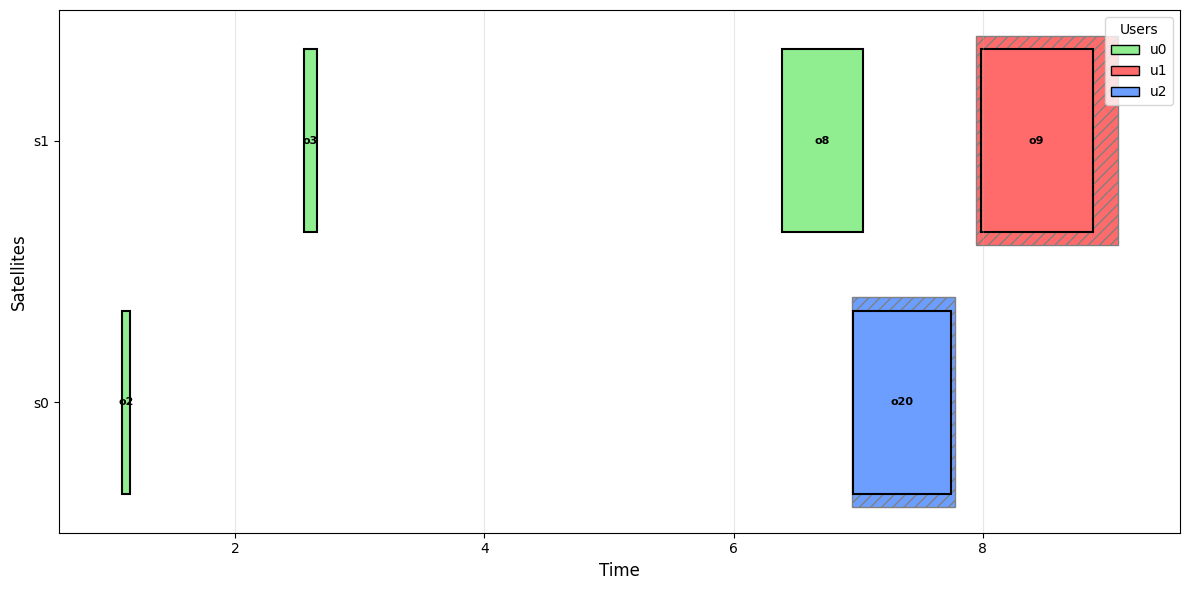

In [12]:
plan_psi, reward_psi, msg_psi = psi_parallel_auction(eoscp)
print(f"Reward total (PSI EOSCP) : {reward_psi}")
print(f"Messages sent (PSI EOSCP) : {msg_psi}")
visualize_plan(plan_psi, eoscp)
plt.show()

### Enchères séquentielles (SSI)

Dans le protocole SSI, les utilisateurs exclusifs calculent individuellement leur propre plan d'allocation sur leurs requètes. Puis, pour chaque requête de l'instance, en suivant un certain ordre (ici sur la date de fin des requètes comme dans l'article, mais d'autres critères peuvent être utilisés), les utilisateurs postent une offre s'il souhaitent obtenir la requête actuellement considérée auprès du planificateur central.  
Le planificateur central sélectionne la meilleure offre pour la requête en cours, l'alloue à l'encherisseur gagnant et met à jour le plan global avec les affectations selectionnées puis passe à la requête suivante.  
Enfin, le planifiacteur central planifie les observations des utilisateurs non exclusifs et calcule le gain total du plan global final.

In [13]:
def ssi_sequential_auction(instance: EOSCP):
    """
    Algorithme d'enchères séquentielles
    Retour:
      - solution sous la forme {satellite_id: [(observation_id, t_start), ...]}
      - reward total
      - nombre de messages envoyés
    """

    u0 = instance.users["u0"]
    exclusive_users: List[User] = [u for uid, u in instance.users.items() if uid != "u0" and len(u.exclusives) > 0]
    msg_sent = 0

    new_user_plans: Dict[str, Dict[str, List[Tuple[Observation, float]]]] = {}
    for u in exclusive_users:
        new_user_plans[u.id] = {}
        for s in instance.satellites.keys():
            new_user_plans[u.id][s] = []

    # Chaque user exclusif calcule son plan initial M_u = solve(P[u]) (avec glouton sur ses obs)
    user_plans: Dict[str, Dict[str, List[Tuple[Observation, float]]]] = {}
    for u in exclusive_users:
        obs_u = [o for o in instance.observations.values() if o.user_id == u.id]
        Mu, _ = greedy_schedule(obs_u, instance.satellites, base_plan=None)
        user_plans[u.id] = Mu

    # Tri des requêtes par t_end croissante ou t_start croissant en cas d'égalité
    list_requests = [r for r in instance.requests]
    request_sort_key = lambda rid: (instance.requests[rid].t_end, instance.requests[rid].t_start)
    sorted_requests = sorted(list_requests, key=request_sort_key)
    
    won_requests: Set[str] = set()
    global_plan: Dict[str, List[Tuple[Observation, float]]] = {sid: [] for sid in instance.satellites}

    for r in sorted_requests:
        best_u: Optional[User] = None
        best_bid: float = -math.inf
        best_sigma: Optional[Tuple[Observation, float]] = None

        # chaque exclusif calcule son bid sur cette requête, avec son plan courant Mu
        for u in exclusive_users:
            Mu = user_plans[u.id]
            b, sigma, msg_sent = bid_request_for_user(instance, u, instance.requests[r], Mu, msg_sent)
            if b > best_bid:
                best_bid = b
                best_u = u
                best_sigma = sigma

        # personne ne peut ou ne veut la prendre dans ses exclusives
        if best_u is None or best_bid == -math.inf or best_sigma is None:
            continue

        o, t = best_sigma
        
        # alloue au gagnant : on l'ajoute au plan central fixé, et on met à jour le plan du gagnant
        insert_sorted(new_user_plans[best_u.id][o.satellite_id], o, t)

        # Agrégation en plan global 
        merge_into(global_plan, new_user_plans[best_u.id])
        msg_sent += 1 # On envoie le plan à tous les utilisateurs
        
        won_requests.add(r)

    # Le planificateur central schedule le reste en respectant les allocations fixées
    obs_u0 = [o for o in instance.observations.values() if o.user_id == u0.id]
    
    # On interdit de resservir les requêtes déjà gagnées dans les exclusives
    u0_plan, _ = greedy_schedule(
        observations=obs_u0,
        satellites=instance.satellites,
        base_plan=None,
        forbidden_requests=won_requests
    ) 

    merge_into(global_plan, u0_plan)
    solution = {
        sid: [(o, t) for (o, t) in lst]
        for sid, lst in global_plan.items()
        if lst
    }
    reward = plan_reward(global_plan)
    return solution, reward, msg_sent




#### Test du protocole SSI

Nous utilisons la fonction de visualisation afin d’obtenir un aperçu de ce à quoi peut ressembler la résolution d’un problème avec le protocole SSI, et de nous assurer de la cohérence des solutions produites. De plus, nous utilisons la même instance que lors du test de la fonction gloutonne pour comparaison.

Reward total (SSI EOSCP) : 85
Messages sent (SSI EOSCP) : 4


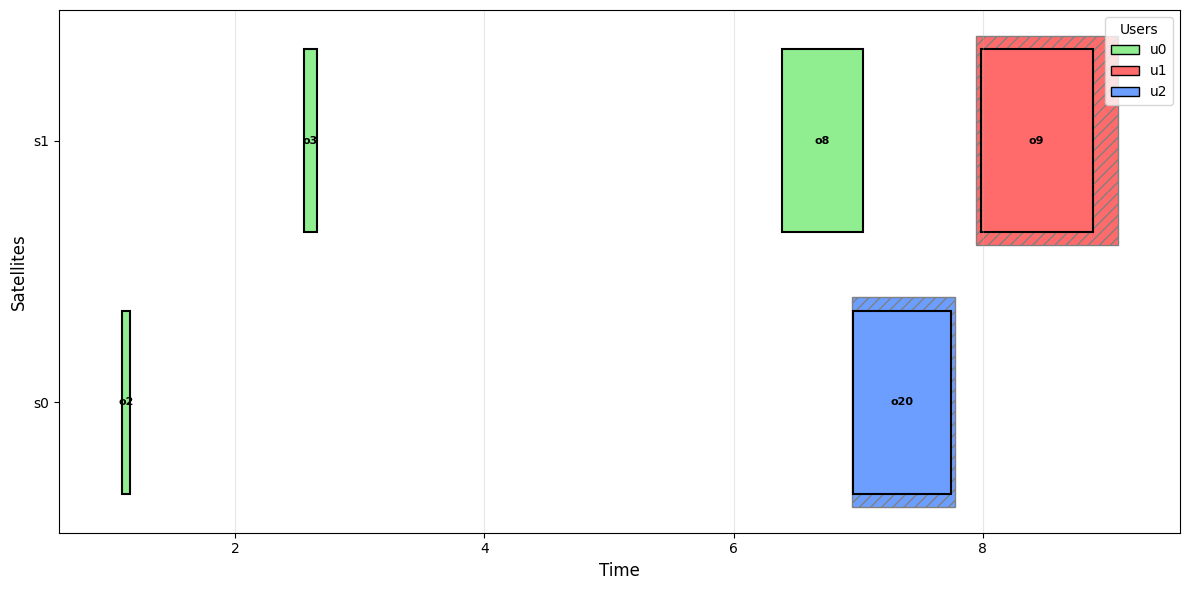

In [14]:
plan_ssi, reward_ssi, msg_ssi = ssi_sequential_auction(eoscp)
print(f"Reward total (SSI EOSCP) : {reward_ssi}")
print(f"Messages sent (SSI EOSCP) : {msg_ssi}")
visualize_plan(plan_ssi, eoscp)
plt.show()

### Enchères séquentielles basées sur le regret

Ce protocole est identique à SSI à l'exception que le planificateur central, au lieu de sélectionner la meilleure offre, il va sélectionner celle qui minimise le regret (c'est à dire celle dont la différence entre la meilleure offre et la seconde meilleure offre est la plus grande).

In [15]:
def regret_ssi_auction(instance: EOSCP):
    """
    Algorithme d'enchères séquentielles basée sur le regret.
    Retour:
      - solution sous la forme {satellite_id: [(observation_id, t_start), ...]}
      - reward total
      - nombre de messages envoyés
    """
    u0 = instance.users["u0"]
    exclusive_users: List[User] = [u for uid, u in instance.users.items() if uid != "u0" and len(u.exclusives) > 0]
    msg_sent = 0

    new_user_plans: Dict[str, Dict[str, List[Tuple[Observation, float]]]] = {}
    for u in exclusive_users:
        new_user_plans[u.id] = {}
        for s in instance.satellites.keys():
            new_user_plans[u.id][s] = []

    # Chaque user exclusif calcule son plan initial M_u = solve(P[u]) (avec glouton sur ses obs)
    user_plans: Dict[str, Plan] = {}
    for u in exclusive_users:
        obs_u = [o for o in instance.observations.values() if o.user_id == u.id]
        Mu, _ = greedy_schedule(obs_u, instance.satellites, base_plan=None)
        user_plans[u.id] = Mu

    remaining_requests: Set[str] = {
        rid for rid, r in instance.requests.items()
    }

    won_requests: Set[str] = set()
    global_plan: Plan = {sid: [] for sid in instance.satellites.keys()}

    while remaining_requests:
        best_r: Optional[str] = None
        best_r_regret: float = -math.inf
        best_r_winner: Optional[User] = None
        best_r_sigma: Optional[Tuple[Observation, float]] = None

        # Évaluer le regret pour chaque requête restante
        for rid in list(remaining_requests):
            r = instance.requests[rid]
            best_bid = -math.inf
            second_bid = -math.inf
            winner: Optional[User] = None
            winner_sigma: Optional[Tuple[Observation, float]] = None

            for u in exclusive_users:
                b, sigma, msg_sent = bid_request_for_user(instance, u, r, user_plans[u.id], msg_sent)
                if b > best_bid:
                    second_bid = best_bid
                    best_bid = b
                    winner = u
                    winner_sigma = sigma
                elif b > second_bid:
                    second_bid = b

            # personne ne peut ou ne veut la prendre dans ses exclusives
            if best_bid == -math.inf or winner is None or winner_sigma is None:
                continue

            regret = best_bid if second_bid == -math.inf else (best_bid - second_bid)

            if regret > best_r_regret:
                best_r_regret = regret
                best_r = rid
                best_r_winner = winner
                best_r_sigma = winner_sigma

        # Si plus aucune requête ne peut être absorbée par des exclusives, on stoppe
        if best_r is None or best_r_winner is None or best_r_sigma is None:
            break

        # alloue au gagnant l'observation correspondante à la requête de regret maximal 
        # (dont la différence entre la meilleure offre et la deuxième meilleure offre est maximale)
        obs, t = best_r_sigma
        insert_sorted(new_user_plans[best_r_winner.id][obs.satellite_id], obs, t)

        # Agrégation en plan global 
        merge_into(global_plan, new_user_plans[best_r_winner.id])
        msg_sent += 1 # On envoie le plan à tous les utilisateurs
        won_requests.add(best_r)
        remaining_requests.remove(best_r)

    # On interdit de resservir les requêtes déjà gagnées dans les exclusives
    obs_u0 = [o for o in instance.observations.values() if o.user_id == u0.id]
    global_plan, _ = greedy_schedule(
        observations=obs_u0,
        satellites=instance.satellites,
        base_plan=global_plan,
        forbidden_requests=won_requests
    )

    solution = {
        sid: [(o, t) for (o, t) in lst]
        for sid, lst in global_plan.items()
        if lst
    }

    reward = plan_reward(global_plan)
    return solution, reward, msg_sent


#### Test du protocole d'enchères séquentielles basées sur le regret

Nous utilisons la fonction de visualisation afin d’obtenir un aperçu de ce à quoi peut ressembler la résolution d’un problème avec le protocole des enchères séquentielles basées sur le regret, et de nous assurer de la cohérence des solutions produites. De plus, nous utilisons la même instance que lors du test de la fonction gloutonne pour comparaison.

Reward total (Regret Based SSI EOSCP) : 85
Messages sent (Regret Based SSI EOSCP) : 5


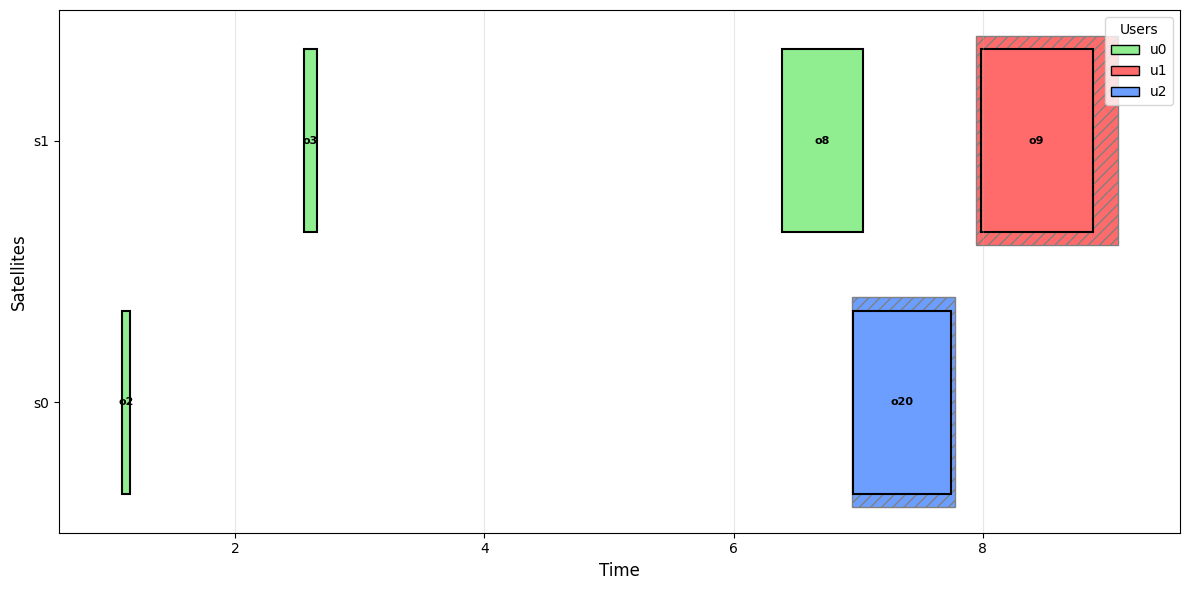

In [16]:
plan_ssi_regret, reward_ssi_regret, msg_ssi_regret = regret_ssi_auction(eoscp)
print(f"Reward total (Regret Based SSI EOSCP) : {reward_ssi_regret}")
print(f"Messages sent (Regret Based SSI EOSCP) : {msg_ssi_regret}")
visualize_plan(plan_ssi_regret, eoscp)
plt.show()

### Comparaison des protocoles d'enchères

Nous testons les différents protocoles impémentés en les comparant entre eux, en prenant comme baseline l’algorithme greedy présenté précédemment. Les comparaisons sont réalisées selon trois critères principaux : les récompenses obtenues (rewards), le temps d’exécution et le nombre de messages échangés.

Afin de modéliser des instances avec beaucoup de conflits, nous utilisons des paramètres similaires à ceux décrits dans la partie résultats de l’article tout en les changeant légèrement pour respecter les contraintes du sujet et de nos machines. Les expériences sont ainsi menées avec 4 satellites, 4 utilisateurs exclusifs (1 par satellite), 10 observations par requête, et un nombre de requêtes variant de 2 à 16, avec un pas de 2.

PSI: 103 (0.001s) | SSI: 103 (0.000s) | REGRET_BASED_SSI: 103 (0.000s) | 
PSI: 155 (0.000s) | SSI: 155 (0.000s) | REGRET_BASED_SSI: 155 (0.001s) | 
PSI: 122 (0.001s) | SSI: 122 (0.000s) | REGRET_BASED_SSI: 122 (0.000s) | 
PSI: 225 (0.001s) | SSI: 225 (0.000s) | REGRET_BASED_SSI: 225 (0.001s) | 
PSI: 162 (0.001s) | SSI: 162 (0.001s) | REGRET_BASED_SSI: 162 (0.001s) | 
PSI: 174 (0.001s) | SSI: 174 (0.001s) | REGRET_BASED_SSI: 174 (0.000s) | 
PSI: 160 (0.001s) | SSI: 160 (0.000s) | REGRET_BASED_SSI: 160 (0.001s) | 


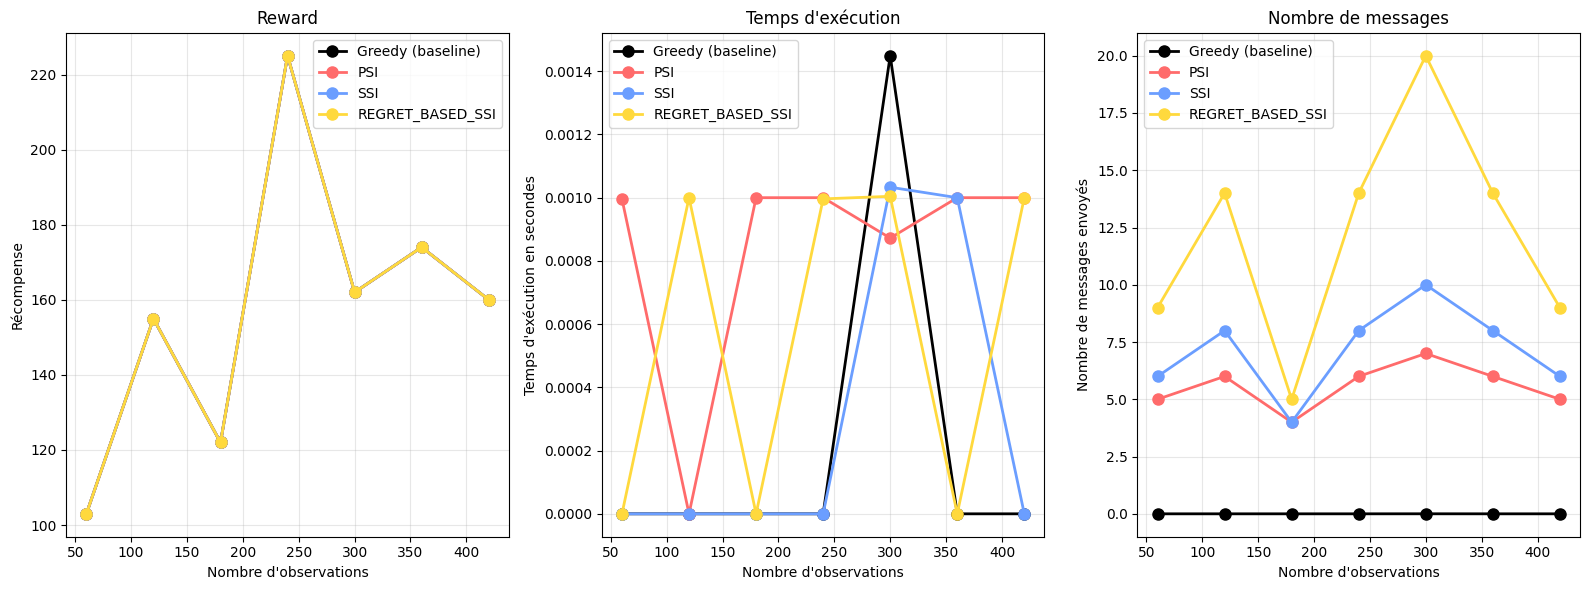

In [17]:
n_sat = 3
n_users = 3
n_obs = 10
algorithms = ['psi', 'ssi', 'regret_based_ssi']

requests_range = list(range(2, 16, 2)) 

results = {
    'n_requests': [],
    'total_observations': [],
    'total_messages': [],
    'greedy_reward': [],
    'greedy_time': [],
}

for algo in algorithms:
    results[f'{algo}_reward'] = []
    results[f'{algo}_time'] = []
    results[f'{algo}_messages'] = []

for n_requests in requests_range:
    total_obs = n_requests * n_users * n_obs
    
    test_instance = generate_instance(
        n_users=n_users,
        n_satellites=n_sat,
        requests_per_user=n_requests,
        observations_per_requests =n_obs
    )
    
    start = time.time()
    obs_all = list(test_instance.observations.values())
    plan_greedy, reward_greedy = greedy_schedule(obs_all, test_instance.satellites)
    time_greedy = time.time() - start
    
    results['n_requests'].append(n_requests)
    results['total_observations'].append(total_obs)
    results['total_messages'].append(0)
    results['greedy_reward'].append(reward_greedy)
    results['greedy_time'].append(time_greedy)
    
    
    for algo in algorithms:

        if algo == 'psi':
            start = time.time()
            plan, reward, msg_sent = psi_parallel_auction(test_instance)
            time_algo = time.time() - start
        elif algo == 'ssi':
            start = time.time()
            plan, reward, msg_sent = ssi_sequential_auction(test_instance)
            time_algo = time.time() - start
        elif algo == 'regret_based_ssi':
            start = time.time()
            plan, reward, msg_sent = regret_ssi_auction(test_instance)
            time_algo = time.time() - start
    
        results[f'{algo}_reward'].append(reward)
        results[f'{algo}_time'].append(time_algo)
        results[f'{algo}_messages'].append(msg_sent)
        
        print(f"{algo.upper()}: {reward:3d} ({time_algo:.3f}s) | ", end="")

    
    print()

df_results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

ax1 = axes[0]
ax1.plot(df_results['total_observations'], df_results['greedy_reward'], 
         'o-', linewidth=2, markersize=8, label='Greedy (baseline)', color='black')

colors = ['#FF6B6B', '#6B9EFF', '#FFD93D', '#9B59B6']
for algo, color in zip(algorithms, colors):
    ax1.plot(df_results['total_observations'], df_results[f'{algo}_reward'], 
             'o-', linewidth=2, markersize=8, label=algo.upper(), color=color)

ax1.set_xlabel("Nombre d'observations")
ax1.set_ylabel('Récompense')
ax1.set_title('Reward')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)


ax2 = axes[1]
ax2.plot(df_results['total_observations'], df_results['greedy_time'], 
         'o-', linewidth=2, markersize=8, label='Greedy (baseline)', color='black')

for algo, color in zip(algorithms, colors):
    ax2.plot(df_results['total_observations'], df_results[f'{algo}_time'], 
             'o-', linewidth=2, markersize=8, label=algo.upper(), color=color)

ax2.set_xlabel("Nombre d'observations")
ax2.set_ylabel("Temps d'exécution en secondes")
ax2.set_title("Temps d'exécution")
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3, which='both')

ax3 = axes[2]
ax3.plot(df_results['total_observations'], df_results['greedy_time'], 
         'o-', linewidth=2, markersize=8, label='Greedy (baseline)', color='black')

for algo, color in zip(algorithms, colors):
    ax3.plot(df_results['total_observations'], df_results[f'{algo}_messages'], 
             'o-', linewidth=2, markersize=8, label=algo.upper(), color=color)

ax3.set_xlabel("Nombre d'observations")
ax3.set_ylabel("Nombre de messages envoyés")
ax3.set_title("Nombre de messages")
ax3.legend(loc='best')
ax3.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()


On remarque que les différents protocoles trouvent les mêmes solutions que l'algorithme glouton. C'est probablement dû à la nature hautement conflictuelle des instances mais potentiellement aussi au fait que les agents calculent leur plan individuel de manière gloutonne.  

Pour ce qui est des temps de calcul, tous les algorithmes sont très proches. En effet, les agents calculent leur plan individuel rapidement de manière gloutonne et le planificateur central n'a qu'à sélectionner la meilleure offre qui lui est soumis.  

Enfin, concernant le nombre de messages échangés, les différents protocoles restent proches car les utilisateurs font peu d'offres mais quand ce nombre augmente, on remarque que **PSI** est l'algorithme qui utilise le moins de messages et **REGRET_BASED_SSI** celui qui en utilise le plus.  

Ces résultats sont cohérents avec ceux de l'article et du cours.

### Conclusion

Après avoir étudié les approches par DCOP et par enchères, nous observons que les approches par optimisation de contraintes distribuées semblent légèrement meilleures que les approches par enchères. En effet, les récompenses obtenues avec les enchères restent équivalentes à celles de l’algorithme greedy, utilisé comme baseline, tandis que les solutions issues des DCOP ont tendance à obtenir des récompenses légèrement supérieures.

Cependant, le temps de calcul nécessaire pour résoudre les DCOP est très important, alors qu’il reste négligeable pour les approches par enchères. Les performances de nos machines ne nous ont pas permis de tester des instances dépassant 400 observations, le temps de résolution des DCOP devenant alors trop élevé. De plus, pour chaque nombre d’observations, nous n’avons lancé qu’une seule instance, et n’avons donc pas effectué de moyennes sur plusieurs exécutions. Néanmoins, des tests répétés (trois lancements) ont montré des résultats globalement similaires.

Dans l’ensemble, nos résultats restent cohérents avec ceux présentés dans l’article, en mettant en évidence des récompenses relativement proches entre les différentes approches, mais des temps de calcul significativement plus élevés pour les méthodes basées sur les DCOP.
